# Task 4 – Teil 6: Line 3-8 – Engpass und Kapazitätserhöhung

### Aufgabenstellung (Abschnitt 6 des Arbeitsauftrags)

> *Untersuchen Sie gezielt, unter welchen Einspeise- und Lastbedingungen diese Leitung zum thermischen Engpass wird. Falls Sie diese spezifische Leitung durch gezielte Laständerung nicht überlasten können, begründen Sie und wählen eine Alternative.*
> - *Entwickeln Sie vor jeder Kapazitätserhöhung durch kontrollierte Variation von Einspeiseort, Erzeugungsleistung und Last ein nachvollziehbares Szenario, in dem Line 3-8 als erste Leitung ihre thermische Nennstromgrenze erreicht (100 % Auslastung), während die übrigen Leitungen noch darunter liegen. Bestimmen und dokumentieren Sie den Grenzbetriebspunkt sowie die tatsächlichen Ströme, die verwendete Stromgrenze und die prozentuale Belastung aller Leitungen. […]*
> - *Begründen Sie die Leitungsauslegung und `max_i_ka` mit plausiblen Quellen. […] Wenn Sie alternative Nennstromgrenzen als Sensitivität betrachten, kennzeichnen und begründen Sie diese separat.*
> - *Erhöhen Sie anschließend die Übertragungskapazität mit mindestens einer technisch begründeten Maßnahme […]. Belegen Sie die geänderten Parameter und vergleichen Sie Vorher und Nachher unter identischen Randbedingungen.*
> - *Bewerten Sie […] die Auswirkungen Ihrer Maßnahme auf Lastflussverteilung, Spannungen an allen Bussen, Verluste und mögliche neue Engpässe. Erklären Sie, ob die Maßnahme den Engpass tatsächlich entschärft oder lediglich verlagert.*
>
> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1–S3.*

| Anforderung | wo |
|---|---|
| Überlastung durch Laständerung? Begründung und Alternative | Abschnitt 2 |
| Szenario durch Variation von Einspeiseort, Leistung und Last (Sweep) | Abschnitt 3 |
| Grenzbetriebspunkt mit Strömen, Stromgrenze und Auslastung aller Leitungen | Abschnitt 3.3 |
| alle Schalterstellungen S1–S3 | Abschnitte 2, 4, 6 und 7 |
| Begründung von Leitungsauslegung und `max_i_ka` | Abschnitt 1.2 |
| Sensitivität der Stromgrenze (getrennt gekennzeichnet) | Abschnitt 5 |
| Kapazitätserhöhung mit belegten Parametern, Vorher/Nachher | Abschnitt 6 |
| Lastflussverteilung, Spannungen, Verluste, neue Engpässe; entschärft oder verlagert? | Abschnitte 6 und 7 |

### Vorgehen

- **Netz:** CIGRE-MV-Referenznetz ohne DER (`create_cigre_network_mv(with_der=False)`), statische Bemessungslasten. Es geht nur um die Grenzen von Line 3-8; Profile, eigene Anlagen und die Ortsnetz-Erweiterung aus Teil 2 bis 5 werden bewusst nicht verwendet.
- **Statische Lastflüsse:** Last und Einspeisung werden **linear in kleinen Schritten** erhöht (Last in Schritten von 2 %, Einspeisung in Schritten von 0,1 MW). So werden nichtlineare Zusammenhänge sichtbar, etwa der Nulldurchgang des Stroms bei Lastflussumkehr oder der überproportionale Anstieg von Verlusten und Spannung.

### Aufbau

1. Referenznetz und Line 3-8
2. Laständerung allein
3. Einspeisung an der Leitung und Grenzbetriebspunkt
4. Alle Schalterstellungen
5. Sensitivität der Stromgrenze
6. Kapazitätserhöhung
7. Entschärft oder verlagert?
8. Fazit

## Importe und Hilfsfunktionen

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import pandapower as pp
import pandapower.networks as pn
import matplotlib.pyplot as plt

import plots
import netplan
import szenarien as sz

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

BASIS = pn.create_cigre_network_mv(with_der=False)
LEITUNG = "Line 3-8"
LEITUNGEN = list(BASIS.line["name"])
MS_BUSSE = [b for b in BASIS.bus["name"] if b != "Bus 0"]
KEYS = sz.KEYS                                            # "000" … "111" = S1, S2, S3 offen/geschlossen
LABEL = {k: sz.label(k, kurz=True) for k in KEYS}
P_MAX, DP = 15.0, 0.1                                     # Einspeisung 0 … 15 MW in Schritten von 0,1 MW
LF_HAUPT = 0.6                                            # Hauptszenario: 60 % der Bemessungslast

In [2]:
def netz(lf=1.0, key="000", leitung=None):
    """Referenznetz mit Lastfaktor lf, Schaltzustand key und optional geänderter Line 3-8 (Funktion net → None)."""
    n = copy.deepcopy(BASIS)
    n.load[["p_mw", "q_mvar"]] *= lf
    for s, c in zip(("S1", "S2", "S3"), key):
        n.switch.loc[n.switch["name"] == s, "closed"] = c == "1"
    if leitung is not None:
        leitung(n)
    return n

def einspeisung(n, bus, p_mw, cosphi=1.0):
    """Erzeuger 'G' an bus setzen (anlegen oder ändern); cos φ < 1: untererregt (Blindleistungsbezug)."""
    q = -p_mw * np.tan(np.arccos(cosphi))
    idx = n.sgen.index[n.sgen["name"] == "G"]
    b = int(n.bus.index[n.bus["name"] == bus][0])
    if len(idx):
        n.sgen.loc[idx, ["bus", "p_mw", "q_mvar"]] = [b, p_mw, q]
    else:
        pp.create_sgen(n, b, p_mw=p_mw, q_mvar=q, name="G")

def ergebnis(n):
    """Lastfluss rechnen; Rückgabe: Auslastungen aller Leitungen [%], Spannungen [pu], Verluste [MW] oder None."""
    try:
        pp.runpp(n, init="results" if len(n.res_bus) else "auto")
    except pp.LoadflowNotConverged:
        try:
            pp.runpp(n, init="flat")
        except pp.LoadflowNotConverged:
            return None
    return (pd.Series(n.res_line.loading_percent.to_numpy(), index=n.line["name"]),
            pd.Series(n.res_bus.vm_pu.to_numpy(), index=n.bus["name"]),
            float(n.res_line.pl_mw.sum() + n.res_trafo.pl_mw.sum()))

def sweep_last(key="000", lf_werte=np.arange(0, 2.0001, 0.02)):
    """Lastfaktor linear erhöhen; Rückgabe: DataFrame (Index lf) mit Auslastung aller Leitungen."""
    zeilen = {}
    for lf in lf_werte:
        e = ergebnis(netz(lf, key))
        if e:
            zeilen[round(lf, 3)] = e[0]
    return pd.DataFrame(zeilen).T

def sweep_einspeisung(bus, lf=LF_HAUPT, key="000", cosphi=1.0, leitung=None, p_werte=None):
    """Einspeisung an bus linear erhöhen; Rückgabe: DataFrame (Index P) mit Auslastungen, U min/max MS und Verlusten."""
    p_werte = np.arange(0, P_MAX + 1e-9, DP) if p_werte is None else p_werte
    n = netz(lf, key, leitung)
    zeilen = {}
    for p in p_werte:
        einspeisung(n, bus, p, cosphi)
        e = ergebnis(n)
        if e is None:
            break
        l, u, v = e
        zeilen[round(p, 3)] = pd.concat([l, pd.Series({"U min MS [pu]": u[MS_BUSSE].min(), "U max MS [pu]": u[MS_BUSSE].max(),
                                                     "Verluste [MW]": v})])
    return pd.DataFrame(zeilen).T

def grenze(df):
    """Erster Schnittpunkt einer Leitung mit 100 % (linear zwischen den Stützstellen interpoliert)."""
    l = df[LEITUNGEN]
    ueber = l.max(axis=1) >= 100
    if not ueber.any():
        return {"Grenzleistung [MW]": np.nan, "erste Leitung": "keine (bis 15 MW)", "zweite Leitung": "", "Auslastung zweite Leitung [%]": np.nan}
    i = int(np.argmax(ueber.to_numpy()))
    erste = l.iloc[i].idxmax()
    if i == 0:
        p = l.index[0]
    else:
        p0, p1 = l.index[i - 1], l.index[i]
        y0, y1 = l[erste].iloc[i - 1], l[erste].iloc[i]
        p = p0 + (100 - y0) / (y1 - y0) * (p1 - p0)
    zweite = l.iloc[i].drop(erste).idxmax()
    return {"Grenzleistung [MW]": p, "erste Leitung": erste, "zweite Leitung": zweite,
            "Auslastung zweite Leitung [%]": l.iloc[i][zweite]}

def grenzbetrieb(bus, p, lf=LF_HAUPT, key="000", cosphi=1.0, leitung=None):
    """Netz im Grenzbetriebspunkt (gerechnet)."""
    n = netz(lf, key, leitung)
    einspeisung(n, bus, p, cosphi)
    pp.runpp(n)
    return n

def leitungstabelle(n):
    """Strom, Stromgrenze und Auslastung aller Leitungen."""
    return pd.DataFrame({"Typ": n.line["std_type"].to_numpy(), "Länge [km]": n.line["length_km"].to_numpy(),
                         "parallel": n.line["parallel"].to_numpy(),
                         "I [A]": n.res_line.i_ka.to_numpy() * 1000,
                         "I_max [A]": (n.line.max_i_ka * n.line.df * n.line.parallel).to_numpy() * 1000,
                         "Auslastung [%]": n.res_line.loading_percent.to_numpy(),
                         "P von from_bus [MW]": n.res_line.p_from_mw.to_numpy()},
                        index=n.line["name"]).sort_values("Auslastung [%]", ascending=False)

def lastfluss_plot(ax, df, hervor=(LEITUNG, "Line 2-3", "Line 1-2"), x_label="Einspeisung an Bus 8 [MW]", linear=True):
    """Auslastung aller Leitungen über dem Sweep-Parameter; hervorgehobene Leitungen farbig, die übrigen grau."""
    for c in LEITUNGEN:
        if c not in hervor:
            ax.plot(df.index, df[c], color="lightgray", lw=0.8)
    for c, farbe in zip(hervor, ("tab:red", "tab:blue", "tab:green")):
        ax.plot(df.index, df[c], color=farbe, lw=2, label=c)
        if linear and len(df) > 3:                       # lineare Fortsetzung der ersten Stützstellen (gestrichelt)
            x0, x1 = df.index[1], df.index[3]
            m = (df[c].iloc[3] - df[c].iloc[1]) / (x1 - x0)
            ax.plot(df.index, df[c].iloc[1] + m * (df.index - x0), color=farbe, lw=0.8, ls=":")
    ax.axhline(100, color="black", ls="--", lw=1)
    ax.set_xlabel(x_label)
    ax.set_ylabel("Auslastung [%]")
    ax.grid(alpha=0.3)

## 1 Referenznetz und Line 3-8

### 1.1 Netz und Lasten

CIGRE-MV ohne DER mit den Bemessungslasten (Wohnen und Gewerbe je Bus):

In [3]:
lasten = BASIS.load.assign(Bus=BASIS.bus.loc[BASIS.load.bus, "name"].to_numpy()).groupby("Bus", sort=False)[["p_mw", "q_mvar"]].sum()
lasten.loc["Summe"] = lasten.sum()
display(lasten.round(3).T)
print("Line 3-8:")
BASIS.line.loc[BASIS.line["name"] == LEITUNG, ["name", "std_type", "from_bus", "to_bus", "length_km", "r_ohm_per_km", "x_ohm_per_km",
                                               "c_nf_per_km", "max_i_ka", "parallel"]]

Bus,Bus 1,Bus 3,Bus 4,Bus 5,Bus 6,Bus 8,Bus 10,Bus 11,Bus 12,Bus 14,Bus 7,Bus 9,Bus 13,Summe
p_mw,19.839,0.502,0.432,0.728,0.548,0.587,0.543,0.330,20.010,0.540,0.076,0.574,0.034,44.742
q_mvar,4.637,0.209,0.108,0.182,0.137,0.147,0.161,0.083,4.693,0.258,0.047,0.356,0.021,11.040


Line 3-8:


,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka,parallel
9,Line 3-8,CABLE_CIGRE_MV,3,8,1.3,0.501,0.716,151.1749,0.145,1


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,140.6,145.0,97.0,4.5
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,139.9,145.0,96.5,4.5
Line 3-8,CABLE_CIGRE_MV,1.3,1.0,69.8,145.0,48.1,2.1
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,54.5,145.0,37.6,1.7
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,48.6,145.0,33.6,1.4
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,40.7,145.0,28.1,1.3
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,28.2,145.0,19.5,0.9
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,17.6,145.0,12.1,0.5
Line 12-13,OHL_CIGRE_MV,4.9,1.0,18.5,195.0,9.5,0.6


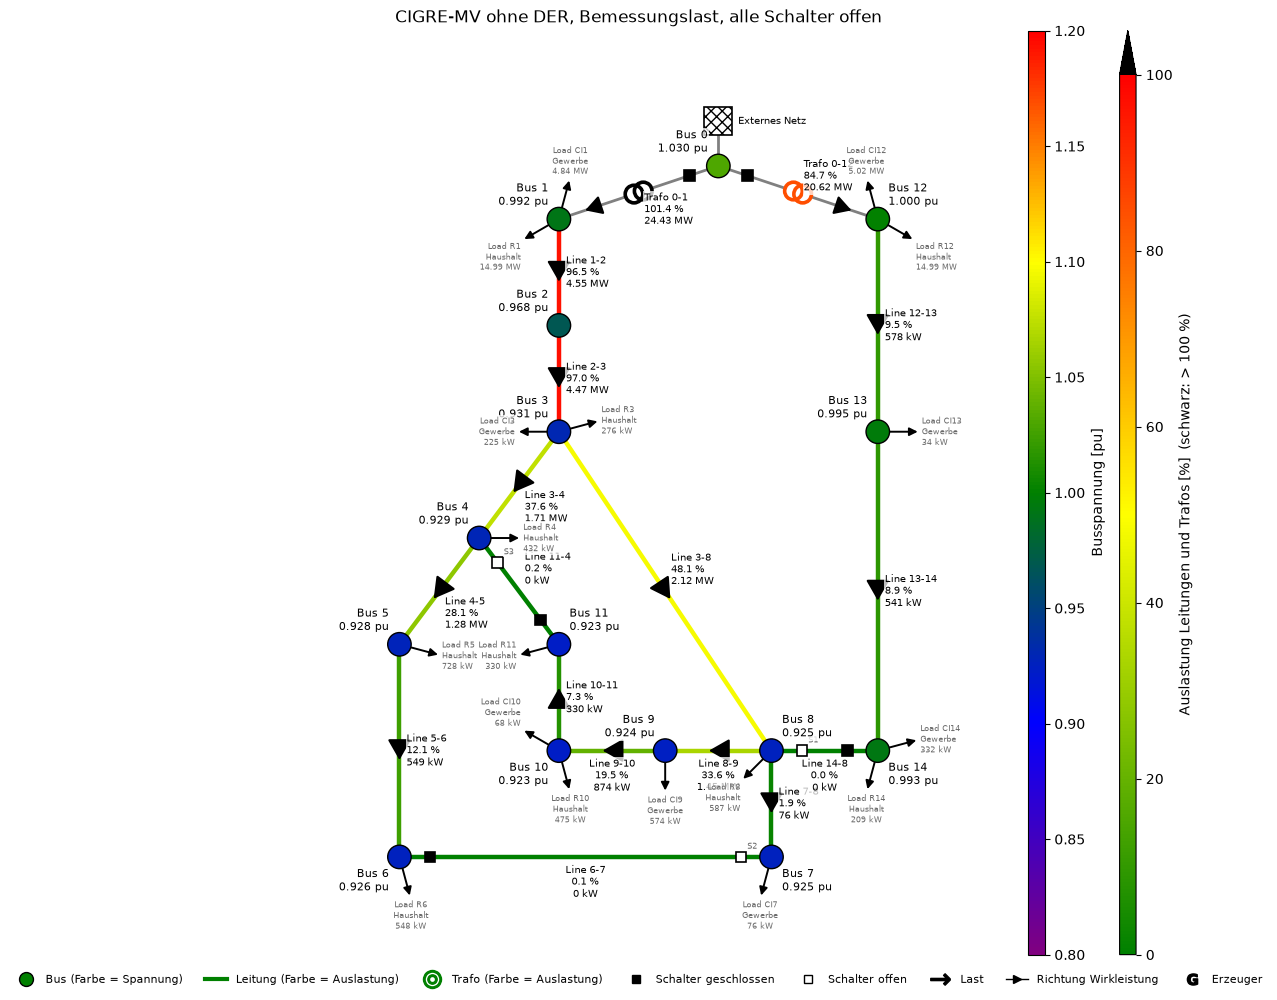

In [4]:
n0 = netz(1.0)
pp.runpp(n0)
display(plots.table(leitungstabelle(n0), decimals=1))
_ = netplan.plot_static(n0, title="CIGRE-MV ohne DER, Bemessungslast, alle Schalter offen")

**Ausgangslage bei Bemessungslast:**

- Die großen Lasten sitzen an den Trafo-Sammelschienen: Bus 1 mit 19,8 MW und Bus 12 mit 20,0 MW. Das sind zusammengefasste Wohn- und Gewerbegebiete. An den Bussen 3 bis 11 hängen nur kleine Lasten von 0,1 bis 0,7 MW.
- Abgang 1 (Bus 1 bis 11) ist verkabelt (`CABLE_CIGRE_MV`, 145 A). Abgang 2 (Bus 12 bis 14) und die Kupplung Line 14-8 sind Freileitungen (`OHL_CIGRE_MV`, 195 A).
- Am stärksten ausgelastet sind die vorgelagerten Kabel Line 2-3 und Line 1-2 (97 bzw. 96,5 %, etwa 140 A). Line 3-8 führt nur 70 A (48 %).

### 1.2 Leitungsauslegung und Stromgrenze `max_i_ka`

Line 3-8 ist im Referenznetz als Kabel des Typs `CABLE_CIGRE_MV` modelliert. Die Leitungsdaten stammen aus dem CIGRE-Benchmark für Mittelspannungsnetze [13] und sind in pandapower als Standardtyp hinterlegt [25]:

| Größe | `CABLE_CIGRE_MV` | NA2XS2Y 1×50 12/20 kV [26] | NA2XS2Y 1×70 12/20 kV [26] |
|---|---|---|---|
| Leiterwiderstand R′ | 0,501 Ω/km | 0,641 Ω/km | 0,443 Ω/km |
| Strombelastbarkeit in Erde | **145 A** (`max_i_ka = 0,145`) | 172 A | 210 A |
| thermische Grenzleistung √3 · 20 kV · I | 5,0 MVA | 6,0 MVA | 7,3 MVA |

Die Strombelastbarkeit in Erde gilt nach dem Datenblatt für Dreiecksbündelung, 20 °C Erdbodentemperatur und Belastungsgrad 0,7 (Bezugsbedingungen nach DIN VDE 0276-620 [27]).

**Begründung:**

- Nach dem Leiterwiderstand entspricht das CIGRE-Kabel einem Aluminiumleiter zwischen 50 und 70 mm². Ein VPE-Kabel dieser Größe ist nach Datenblatt in Erde mit 172 bis 210 A belastbar. Die 145 A des Referenznetzes liegen bei 70 bis 85 % davon, sind also eher vorsichtig angesetzt. Das ist plausibel, weil reale Verlegebedingungen (Häufung mehrerer Kabel, wärmerer oder trockener Boden) die Belastbarkeit gegenüber den Bezugsbedingungen senken [28].
- Bei Kabeln bestimmt die thermische Grenzleistung die Übertragungsfähigkeit; sie liegt unter der natürlichen Leistung [19, S. 461 f.]. Kabel lassen sich kaum kurzzeitig überlasten, weil ihre Isolierung zugleich als Wärmedämmung wirkt [19, S. 439]. Die Stromgrenze ist deshalb eine harte Grenze.
- Querschnitte und Dauerstrombelastbarkeit sind genormt; ein berechneter Querschnitt wird auf den nächsthöheren genormten Querschnitt aufgerundet [19, S. 799 f.].
- **`max_i_ka = 0,145 kA` wird in allen Abschnitten außer der Sensitivität (Abschnitt 5) unverändert verwendet.**
- Auffällig ist der hohe Leitungsbelag X′ = 0,716 Ω/km des CIGRE-Kabels; ein typisches Einleiterkabel liegt bei etwa 0,11 bis 0,13 Ω/km (pandapower-Standardtypen [25]). Für die Stromgrenze spielt das keine Rolle, wohl aber für die Stromaufteilung in Maschen (Abschnitte 4 und 6).

## 2 Laständerung allein

Alle Lasten werden gemeinsam linear von 0 bis 200 % der Bemessungslast in Schritten von 2 % erhöht, in allen acht Schaltzuständen. Für jede Leitung wird die Auslastung aufgezeichnet.

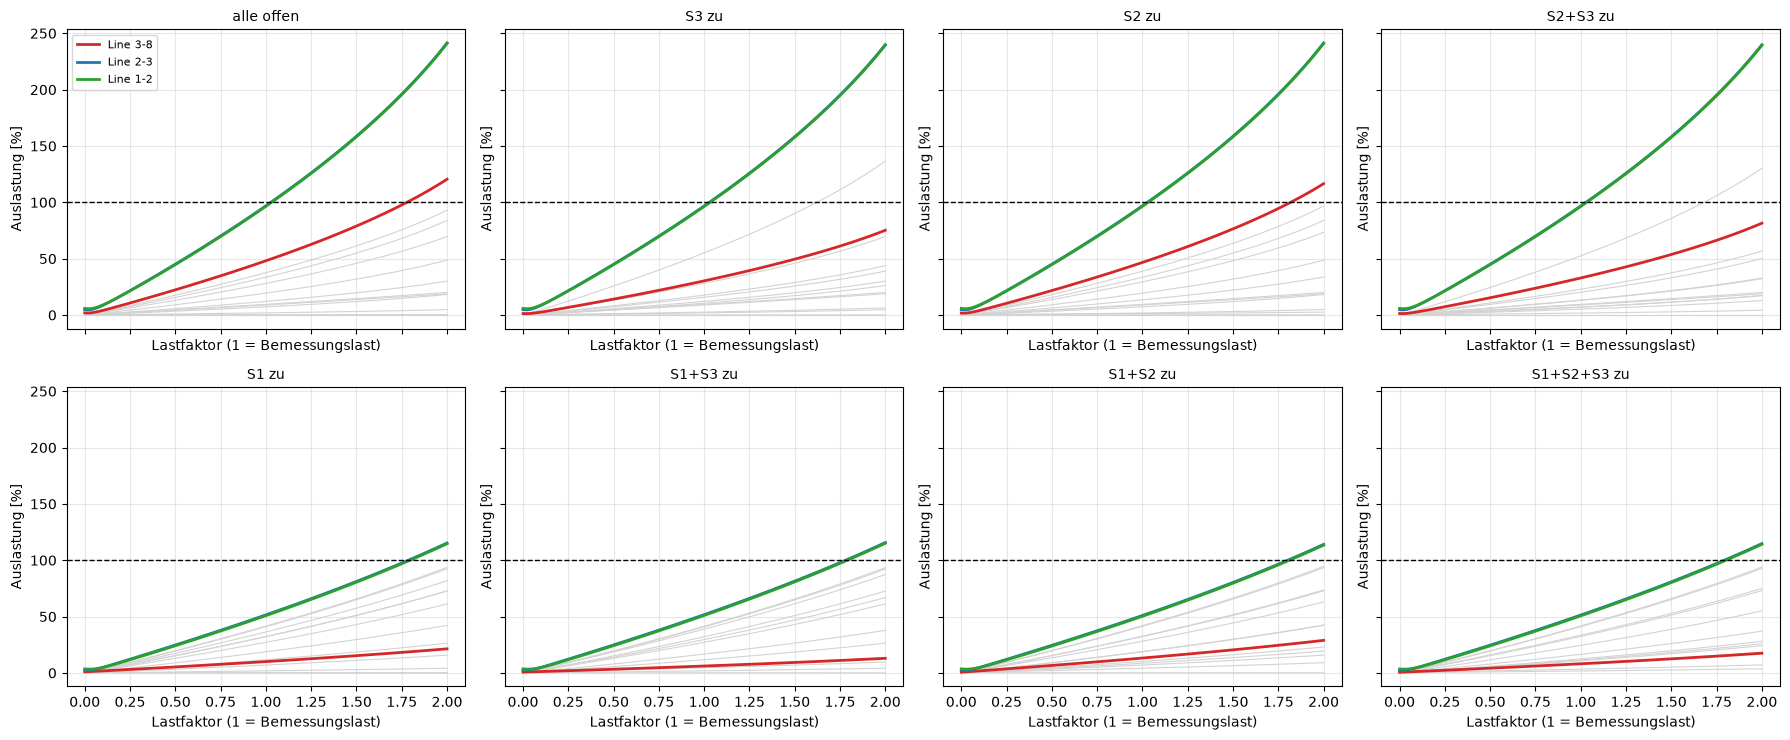

,Lastfaktor bei erster Überlastung,erste Leitung,Line 3-8 dann [%],Line 3-8 bei Bemessungslast [%]
alle offen,1.040000,Line 2-3,50.384280,48.143637
S3 zu,1.040000,Line 2-3,31.743250,30.338819
S2 zu,1.040000,Line 2-3,48.851666,46.684368
S2+S3 zu,1.040000,Line 2-3,34.415987,32.894599
S1 zu,1.800000,Line 2-3,18.845895,10.058203
S1+S3 zu,1.800000,Line 2-3,11.432746,6.141118
S1+S2 zu,1.820000,Line 2-3,25.713069,13.207405
S1+S2+S3 zu,1.800000,Line 2-3,15.401955,8.127911


In [5]:
last = {k: sweep_last(k) for k in KEYS}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes.flat, KEYS):
    lastfluss_plot(ax, last[k], x_label="Lastfaktor (1 = Bemessungslast)", linear=False)
    ax.set_title(LABEL[k], fontsize=10)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

zeilen = {}
for k in KEYS:
    df = last[k][LEITUNGEN]
    ueber = df.max(axis=1) >= 100
    i = int(np.argmax(ueber.to_numpy()))
    zeilen[LABEL[k]] = {"Lastfaktor bei erster Überlastung": df.index[i], "erste Leitung": df.iloc[i].idxmax(),
                        "Line 3-8 dann [%]": df.iloc[i][LEITUNG], "Line 3-8 bei Bemessungslast [%]": df.loc[1.0, LEITUNG]}
plots.table(pd.DataFrame(zeilen).T, decimals=2)

**Ergebnis Laständerung:**

- In **keinem** Schaltzustand erreicht Line 3-8 als erste Leitung 100 %. Immer ist Line 2-3 zuerst überlastet:
  - S1 offen: schon bei 104 % der Bemessungslast; Line 3-8 liegt dann bei 32 bis 50 %.
  - S1 zu: erst bei 180 %, weil Abgang 2 über S1 einen Teil der Last von Abgang 1 übernimmt; Line 3-8 liegt dann bei 11 bis 26 %.
- **Begründung:** In einem Strahlennetz fließt im ersten Abschnitt einer mehrfach belasteten Leitung die Summe aller Abnehmerströme dahinter [19, S. 803 ff.]. Über Line 2-3 laufen die Lasten von Bus 3 bis 11, über Line 3-8 nur die von Bus 7 bis 11. Jede Lasterhöhung hinter Line 3-8 erhöht Line 2-3 mindestens genauso stark. Da Line 2-3 schon bei Bemessungslast fast an der Grenze liegt, kann Line 3-8 durch Laständerung nie zuerst an die Grenze kommen.
- Die Kurven verlaufen nahezu linear, mit leicht überproportionalem Anstieg bei hoher Last (Spannungsfall und Verluste wachsen mit).
- **Alternative:** Eine Einspeisung kehrt die Flussrichtung um. Wird sie am Ende von Line 3-8 angeschlossen, fließt ihre Leistung zuerst über Line 3-8, und die Lasten in Abgang 1 entlasten die vorgelagerten Leitungen.

## 3 Einspeisung an der Leitung und Grenzbetriebspunkt

### 3.1 Einspeiseort

Ein Erzeuger (cos φ = 1) wird nacheinander an jeden Bus von Abgang 1 gesetzt und seine Leistung linear von 0 bis 15 MW in Schritten von 0,1 MW erhöht (60 % Last, alle Schalter offen). Je Ort: welche Leitung erreicht zuerst 100 %, bei welcher Leistung, und wie hoch ist dann die am zweitstärksten ausgelastete Leitung?

In [6]:
ORTE = [f"Bus {i}" for i in range(2, 12)]
ort = {b: sweep_einspeisung(b) for b in ORTE}
ort_tab = pd.DataFrame({b: grenze(df) for b, df in ort.items()}).T
plots.table(ort_tab, decimals=2)

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
Bus 2,7.744851,Line 1-2,Line 2-3,53.259134
Bus 3,7.805799,Line 2-3,Line 1-2,101.460400
Bus 4,6.233062,Line 3-4,Line 2-3,72.297186
Bus 5,5.978720,Line 4-5,Line 3-4,95.455537
Bus 6,5.563370,Line 5-6,Line 4-5,92.318899
Bus 7,5.269646,Line 7-8,Line 3-8,77.495429
Bus 8,6.488459,Line 3-8,Line 2-3,75.733687
Bus 9,6.084807,Line 8-9,Line 3-8,92.781379
Bus 10,5.752199,Line 9-10,Line 8-9,94.467010
Bus 11,5.419029,Line 10-11,Line 9-10,95.253877


**Ergebnis Einspeiseort:**

- Überlastet wird immer zuerst die Leitung, über die der Erzeuger angeschlossen ist. Nur bei Einspeisung an **Bus 8** ist das Line 3-8 (bei 6,49 MW, nächste Leitung Line 2-3 mit 76 %).
- **Bus 7:** Line 7-8 kommt zuerst (5,27 MW).
- **Bus 9:** Line 8-9 kommt zuerst (6,08 MW), Line 3-8 liegt dann schon bei 93 %. Die Leistung fließt über Line 8-9 und Line 3-8 nacheinander, deshalb sind beide fast gleich ausgelastet.
- **Bus 2 und Bus 3:** Line 1-2 bzw. Line 2-3 kommt zuerst.
- Bus 8 ist der Kabelverteiler, an dem Line 3-8, 7-8, 8-9 und die Kupplung 14-8 zusammenkommen. Eine Erzeugungsanlage mit eigenem Anschlusskabel dorthin ist eine realistische Annahme.

### 3.2 Leistung und Last am Einspeiseort Bus 8

Bus 8 ist das Ende von Line 3-8. Die Einspeisung wird linear erhöht, für drei Lastfälle (30 %, 60 %, 100 % der Bemessungslast). Rot: Line 3-8, blau und grün: die vorgelagerten Leitungen 2-3 und 1-2, grau: alle übrigen. Die gepunkteten Linien setzen den Anfang jeder Kurve linear fort; der Abstand zur tatsächlichen Kurve zeigt, wo der Zusammenhang nichtlinear wird.

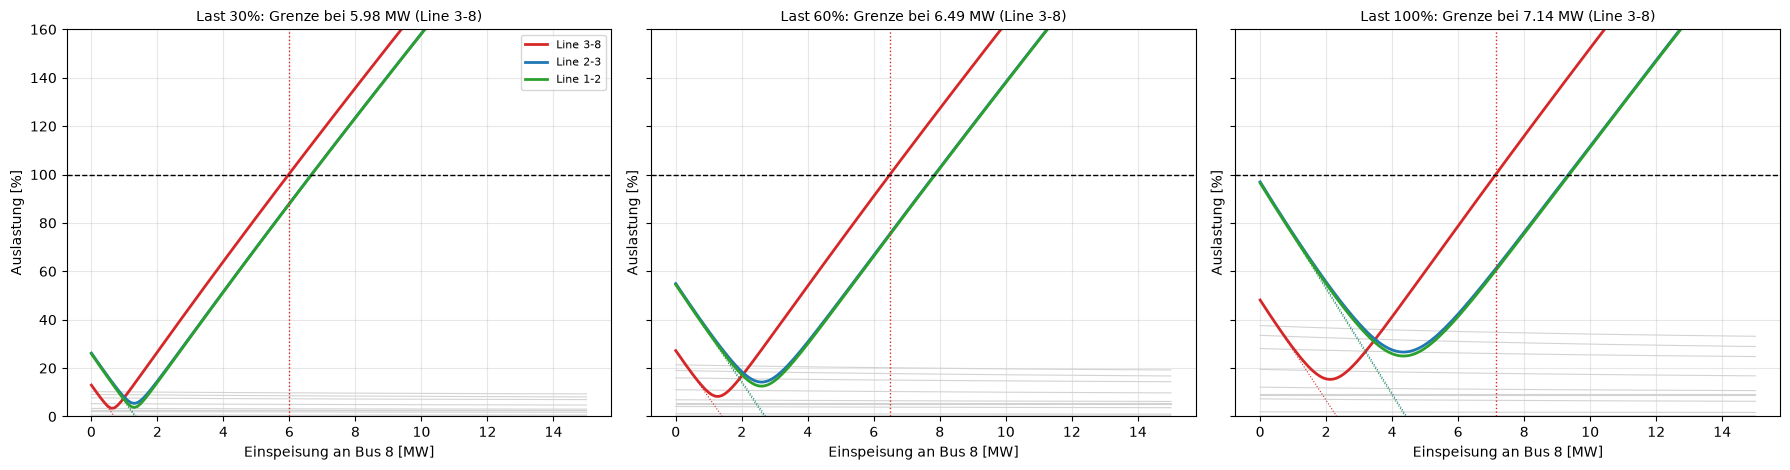

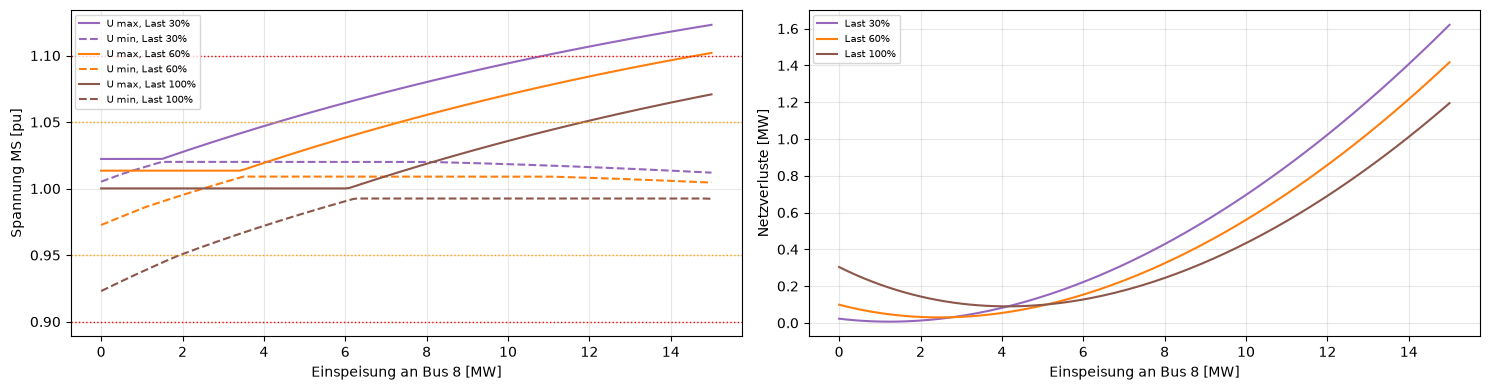

In [7]:
LASTFAELLE = [0.3, 0.6, 1.0]
bus8 = {lf: sweep_einspeisung("Bus 8", lf) for lf in LASTFAELLE}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, lf in zip(axes, LASTFAELLE):
    lastfluss_plot(ax, bus8[lf])
    g = grenze(bus8[lf])
    ax.axvline(g["Grenzleistung [MW]"], color="tab:red", ls=":", lw=1)
    ax.set_title(f"Last {lf:.0%}: Grenze bei {g['Grenzleistung [MW]']:.2f} MW ({g['erste Leitung']})", fontsize=10)
    ax.set_ylim(0, 160)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for lf, farbe in zip(LASTFAELLE, ("tab:purple", "tab:orange", "tab:brown")):
    axes[0].plot(bus8[lf].index, bus8[lf]["U max MS [pu]"], color=farbe, label=f"U max, Last {lf:.0%}")
    axes[0].plot(bus8[lf].index, bus8[lf]["U min MS [pu]"], color=farbe, ls="--", label=f"U min, Last {lf:.0%}")
    axes[1].plot(bus8[lf].index, bus8[lf]["Verluste [MW]"], color=farbe, label=f"Last {lf:.0%}")
for v, c in ((0.90, "red"), (0.95, "orange"), (1.05, "orange"), (1.10, "red")):
    axes[0].axhline(v, color=c, ls=":", lw=1)
axes[0].set_ylabel("Spannung MS [pu]")
axes[1].set_ylabel("Netzverluste [MW]")
for ax in axes:
    ax.set_xlabel("Einspeisung an Bus 8 [MW]")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

zeilen = {}
for lf in LASTFAELLE:
    for cosphi in (1.0, 0.95):
        df = bus8[lf] if cosphi == 1.0 else sweep_einspeisung("Bus 8", lf, cosphi=cosphi)
        g = grenze(df)
        p = g["Grenzleistung [MW]"]
        zeilen[(f"{lf:.0%}", f"cos φ = {cosphi}" + (" untererregt" if cosphi < 1 else ""))] = {
            **g, "U max MS im Grenzpunkt [pu]": np.interp(p, df.index, df["U max MS [pu]"])}
plots.table(pd.DataFrame(zeilen).T, decimals=3)

**Ergebnis Leistungs-Sweep an Bus 8:**

- **Nichtlinearer Verlauf am Anfang:** Die Auslastung von Line 3-8 sinkt zunächst, erreicht ein Minimum und steigt dann wieder. Am Minimum deckt der Erzeuger gerade die Lasten von Bus 7 bis 11; danach kehrt sich der Fluss auf Line 3-8 um (von Bus 8 zu Bus 3). Je nach Last liegt der Nulldurchgang bei etwa 0,6, 1,2 bzw. 2,2 MW. Dasselbe passiert später auf Line 2-3 und 1-2, sobald der Erzeuger die ganze Last von Abgang 1 hinter Bus 2 deckt. Der Strom wird nie ganz null, weil Blindleistung weiter fließt. Die gepunktete lineare Fortsetzung zeigt, wie stark die Kurven an dieser Stelle abknicken.
- **Nach der Umkehr** steigen alle drei Kurven fast linear mit rund 19 Prozentpunkten je MW.
- **Netzverluste:** Sie wachsen quadratisch mit dem Strom, sichtbar an der Parabel. Ihr Minimum liegt dort, wo Einspeisung und Last sich ausgleichen.
- **Spannung:** Die höchste Spannung steigt mit der Einspeisung. Die Knicke entstehen, wenn ein anderer Bus zum Maximum bzw. Minimum wird.
- **Grenzleistung:** Bei 30 / 60 / 100 % Last erreicht Line 3-8 die 100 % bei 5,98 / 6,49 / 7,14 MW. Die nächste Leitung (Line 2-3) liegt dann bei 88 / 76 / 62 %. Je höher die Last, desto mehr Einspeisung nehmen die Lasten in Abgang 1 auf und desto größer ist der Abstand.
- **Spannung im Grenzpunkt:** Bei 30 % Last liegt sie mit 1,064 pu über dem Planungsband 1,05 pu, aber unter der Grenze 1,10 pu. Bei 60 % und 100 % Last liegt sie im Band.
- **cos φ = 0,95 untererregt:** Die Blindleistung senkt die Spannung (um 2 bis 4 Prozentpunkte im Grenzpunkt), erhöht aber den Strom. Line 3-8 erreicht die Grenze deshalb schon bei 5,39 bis 6,06 MW. Die Spannungshaltung über Blindleistung geht also auf Kosten der thermischen Reserve.

### 3.3 Grenzbetriebspunkt (Hauptszenario)

**Szenario:** 60 % der Bemessungslast (etwa ein Werktag zur Mittagszeit), alle Schalter offen, eine neue Erzeugungsanlage am Kabelverteiler Bus 8 mit cos φ = 1, z. B. ein PV-Park mit etwa 7 MWp oder drei Windenergieanlagen. Die Leistung wird so weit erhöht, bis Line 3-8 genau 100 % erreicht. Dokumentiert werden Strom, Stromgrenze und Auslastung aller Leitungen sowie die Spannungen an allen Bussen.

Grenzbetriebspunkt: 6.49 MW an Bus 8, Last 60%, alle Schalter offen


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 3-8,CABLE_CIGRE_MV,1.3,1.0,145.0,145.0,100.0,-5.2
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,109.6,145.0,75.6,-3.8
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,109.1,145.0,75.2,-3.7
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,29.2,145.0,20.1,1.0
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,25.7,145.0,17.7,0.9
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,21.8,145.0,15.0,0.8
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,15.0,145.0,10.3,0.5
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,9.4,145.0,6.5,0.3
Line 12-13,OHL_CIGRE_MV,4.9,1.0,10.9,195.0,5.6,0.3


name,Bus 0,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14
U [pu],1.03,1.0118,1.0209,1.0355,1.0345,1.0338,1.0331,1.0426,1.0427,1.0422,1.0415,1.0414,1.0135,1.0107,1.0090
Winkel [°],0.00,-32.1460,-30.9404,-29.0723,-29.1238,-29.1593,-29.2015,-28.3995,-28.3935,-28.4129,-28.4448,-28.4502,-33.2454,-33.2767,-33.2943


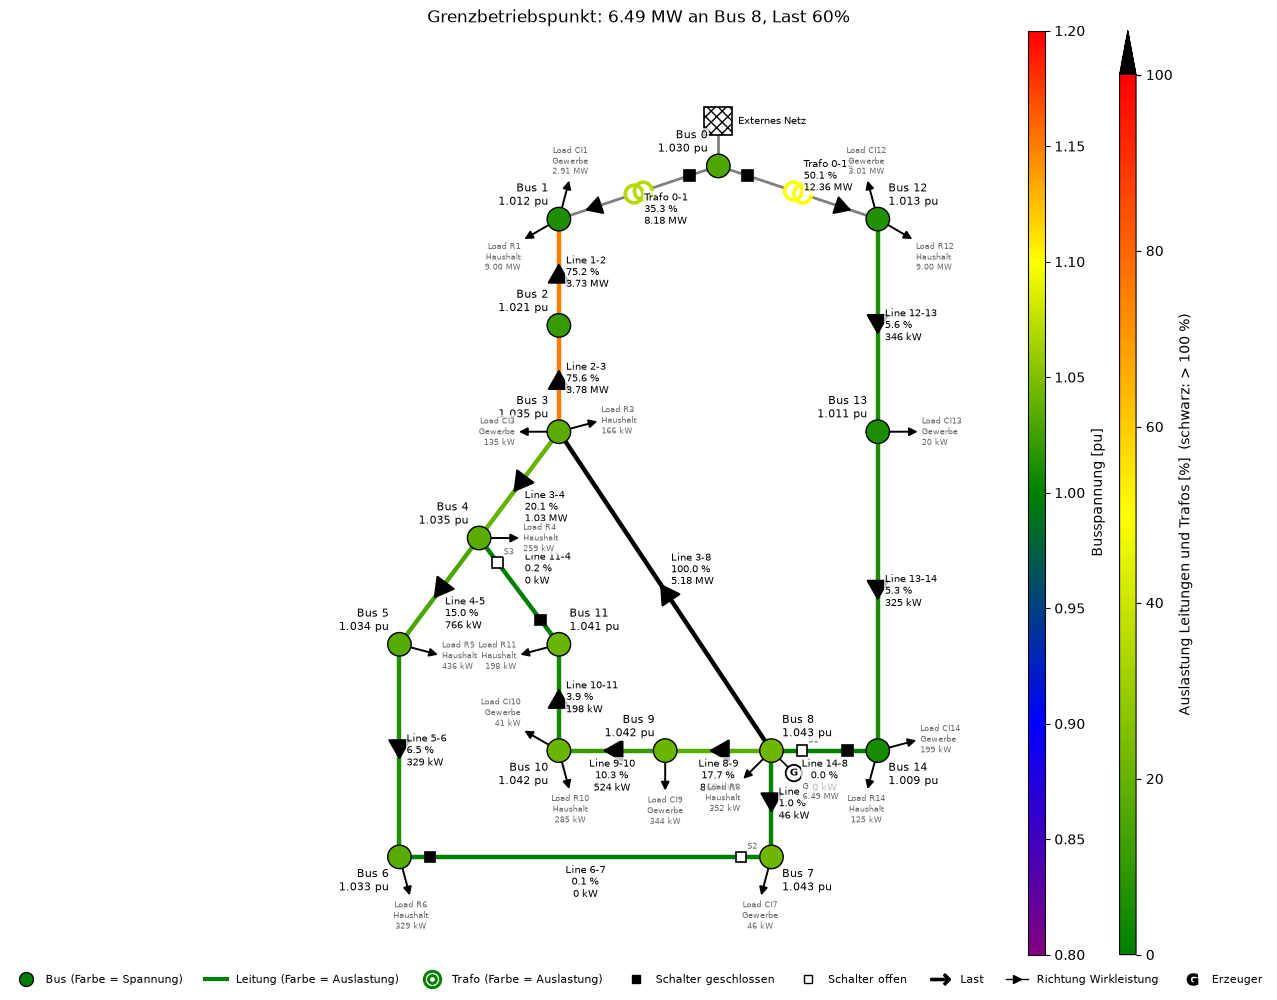

In [8]:
G_HAUPT = grenze(bus8[LF_HAUPT])
P_GRENZ = round(G_HAUPT["Grenzleistung [MW]"], 2)
n_grenz = grenzbetrieb("Bus 8", P_GRENZ)
print(f"Grenzbetriebspunkt: {P_GRENZ:.2f} MW an Bus 8, Last {LF_HAUPT:.0%}, alle Schalter offen")
display(plots.table(leitungstabelle(n_grenz), decimals=1))
spannungen = pd.DataFrame({"U [pu]": n_grenz.res_bus.vm_pu.to_numpy(), "Winkel [°]": n_grenz.res_bus.va_degree.to_numpy()},
                          index=n_grenz.bus["name"])
display(spannungen.T.round(4))
_ = netplan.plot_static(n_grenz, title=f"Grenzbetriebspunkt: {P_GRENZ:.2f} MW an Bus 8, Last {LF_HAUPT:.0%}")

**Grenzbetriebspunkt (Hauptszenario):**

| Größe | Wert |
|---|---|
| Einspeisung an Bus 8 | **6,49 MW**, cos φ = 1 |
| Last | 60 % der Bemessungslast (26,8 MW) |
| Line 3-8 | **145,0 A von 145 A = 100,0 %**, 5,2 MW von Bus 8 zu Bus 3 |
| Line 2-3 / Line 1-2 | 109,6 A / 109,1 A von 145 A = 75,6 % / 75,2 % |
| alle übrigen Leitungen | höchstens 20 % (Line 3-4) |
| Spannungen MS | 1,009 bis 1,043 pu (im Planungsband) |

- Line 3-8 erreicht als erste und einzige Leitung 100 %. Die nächste Leitung hat mit rund 25 Prozentpunkten deutlich Abstand. Damit ist die Forderung der Aufgabe erfüllt.
- Die Stromgrenze ist der unveränderte Wert des Referenznetzes (145 A).
- Die Leistung fließt von Bus 8 über Line 3-8 und weiter über Line 2-3 und 1-2 zu Bus 1. Dort nimmt die große Last (11,9 MW bei 60 %) sie vollständig auf; Trafo 0-1 führt weiter Leistung in Bezugsrichtung (35 %).

## 4 Alle Schalterstellungen

Dasselbe Vorgehen wie in 3.2 (Einspeisung an Bus 8, 60 % Last) für alle acht Schaltzustände. Für Zustände, in denen Line 3-8 nicht zuerst an die Grenze kommt, wird zusätzlich geprüft, ob ein anderer Einspeiseort (Bus 2 bis Bus 14) das ändert.

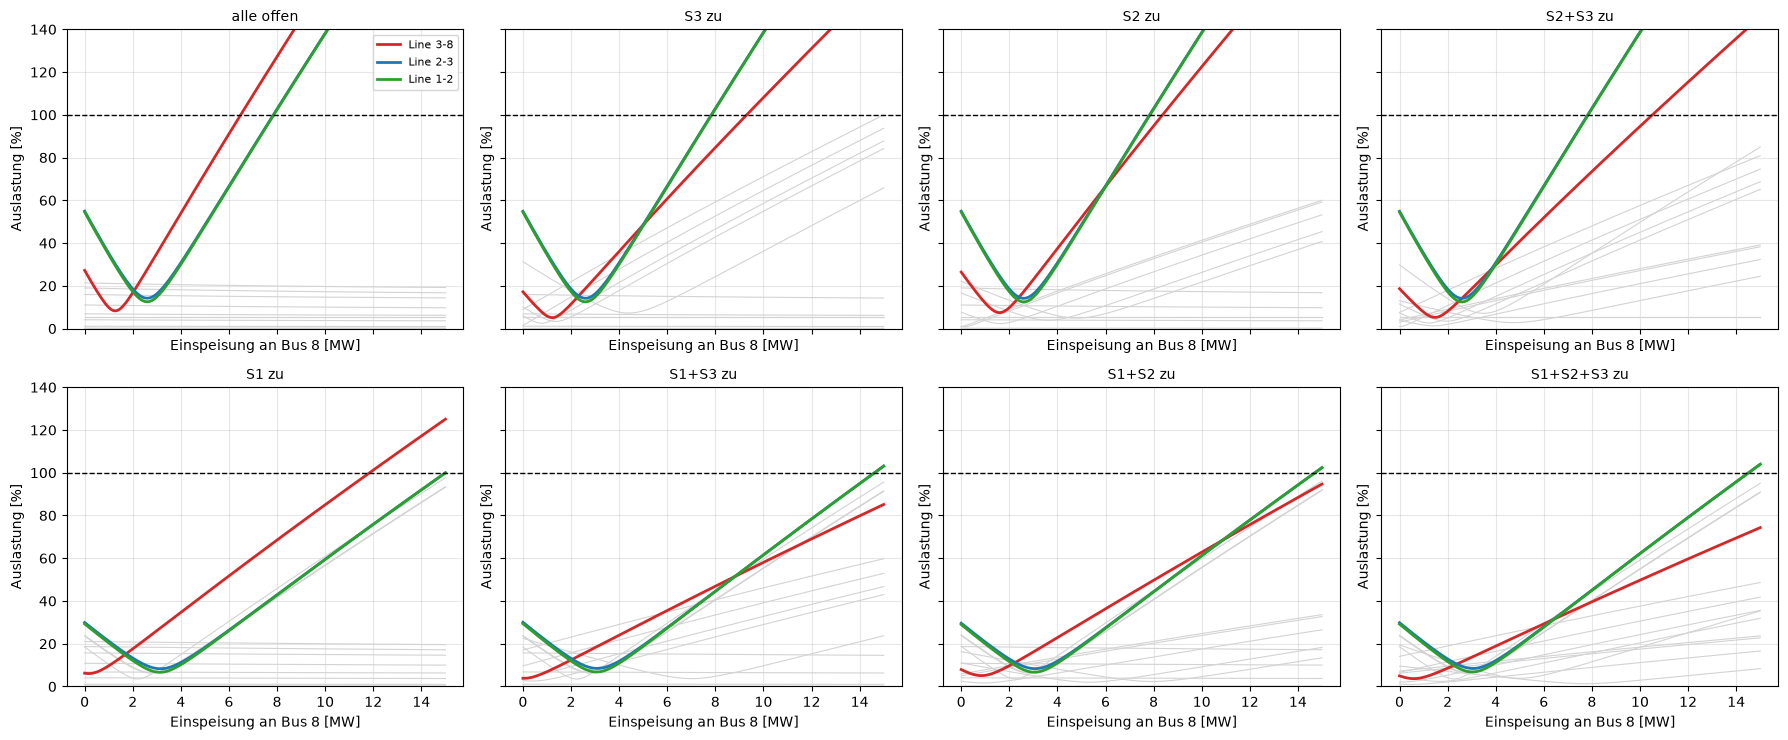

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%],Line 3-8 im Grenzpunkt [%]
alle offen,6.488459,Line 3-8,Line 2-3,75.733687,100.00
S3 zu,7.832455,Line 2-3,Line 1-2,100.946617,82.72
S2 zu,7.833734,Line 2-3,Line 1-2,100.921581,92.47
S2+S3 zu,7.827429,Line 2-3,Line 1-2,101.042366,71.66
S1 zu,11.847162,Line 3-8,Line 1-2,75.061306,100.00
S1+S3 zu,14.617704,Line 1-2,Line 2-3,100.646753,83.13
S1+S2 zu,14.704533,Line 1-2,Line 2-3,100.746340,92.84
S1+S2+S3 zu,14.514219,Line 1-2,Line 2-3,100.677859,71.98


In [9]:
schalter = {k: sweep_einspeisung("Bus 8", key=k) for k in KEYS}
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes.flat, KEYS):
    lastfluss_plot(ax, schalter[k], linear=False)
    ax.set_title(LABEL[k], fontsize=10)
    ax.set_ylim(0, 140)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

s_tab = pd.DataFrame({LABEL[k]: grenze(schalter[k]) for k in KEYS}).T
s_tab["Line 3-8 im Grenzpunkt [%]"] = [np.interp(g, schalter[k].index, schalter[k][LEITUNG]) if not np.isnan(g) else np.nan
                                       for k, g in zip(KEYS, s_tab["Grenzleistung [MW]"].astype(float))]
plots.table(s_tab, decimals=2)

In [10]:
ALLE_ORTE = [f"Bus {i}" for i in range(2, 15)]
zeilen = {}
for k in KEYS:
    if s_tab.loc[LABEL[k], "erste Leitung"] == LEITUNG:
        continue
    for b in ALLE_ORTE:
        g = grenze(sweep_einspeisung(b, key=k))
        if g["erste Leitung"] == LEITUNG:
            zeilen[(LABEL[k], b)] = g
alternativ = pd.DataFrame(zeilen).T
if len(alternativ):
    display(plots.table(alternativ, decimals=2))
else:
    print("In keinem dieser Schaltzustände erreicht Line 3-8 bei Einspeisung an einem anderen Bus zuerst 100 %.")

In keinem dieser Schaltzustände erreicht Line 3-8 bei Einspeisung an einem anderen Bus zuerst 100 %.


**Ergebnis Schalterstellungen:**

| Zustand | erste Leitung bei 100 % | Grenzleistung | Line 3-8 dann |
|---|---|---|---|
| alle offen | **Line 3-8** | 6,49 MW | 100 % |
| S1 zu | **Line 3-8** | 11,85 MW | 100 % |
| S2 und/oder S3 zu | Line 2-3 | 7,83 MW | 72 bis 92 % |
| S1 mit S2 und/oder S3 zu | Line 1-2 | 14,5 bis 14,7 MW | 72 bis 93 % |

- **S1 zu:** Die Einspeisung teilt sich an Bus 8 auf: Ein Teil fließt über Line 3-8 in Abgang 1, ein Teil über die Kupplung und Abgang 2 zur großen Last an Bus 12. Line 3-8 bleibt der Engpass, aber erst bei fast doppelter Leistung.
- **S2 oder S3 zu:** Die Masche schafft einen zweiten Weg von Bus 8 zu Bus 3 (über Bus 7–6–5–4 bzw. Bus 9–10–11–4). Die Leistung teilt sich nach den Impedanzen auf [19, S. 437 f., 806 f.], Line 3-8 wird entlastet. Den ganzen Rückfluss trägt dann Line 2-3, die bei 7,83 MW als erste überlastet ist.
- **S1 mit S2 oder S3:** Beide Effekte zusammen; zuerst wird Line 1-2 überlastet.
- In den Zuständen mit S2 oder S3 erreicht Line 3-8 auch mit einem anderen Einspeiseort (Bus 2 bis 14) nie zuerst 100 %. **Begründung:** Line 3-8 liegt dann in einer Masche, und jede Einspeisung teilt sich auf beide Wege auf. Die Summe beider Wege muss aber über Line 2-3 bzw. 1-2 abfließen, und diese Leitungen erreichen ihre Grenze zuerst. Das Hauptszenario und die Kapazitätserhöhung beziehen sich deshalb auf den Normalschaltzustand (alle offen); die übrigen Zustände werden in Abschnitt 6 und 7 mitgerechnet.

## 5 Sensitivität der Stromgrenze (gesondert gekennzeichnet)

**Achtung:** Dieser Abschnitt ist eine Sensitivität und kein Nachweis eines Engpasses. Eine andere Stromgrenze ändert den Strom auf der Leitung nicht, nur die Bewertung in Prozent. Untersucht wird, wie sich die Grenzleistung im Hauptszenario verschiebt, wenn die Stromgrenze von Line 3-8 linear zwischen 100 und 250 A variiert wird. Markiert sind:

- **145 A:** Wert des Referenznetzes (verwendet in allen anderen Abschnitten)
- **172 A / 210 A:** Datenblattwerte NA2XS2Y 1×50 bzw. 1×70 in Erde unter Bezugsbedingungen [26]
- **ca. 120 A:** Beispiel für ungünstige Verlegebedingungen (Häufung, warmer Boden); die Umrechnungsfaktoren nach DIN VDE 0276-1000 [28] liegen dann unter 1

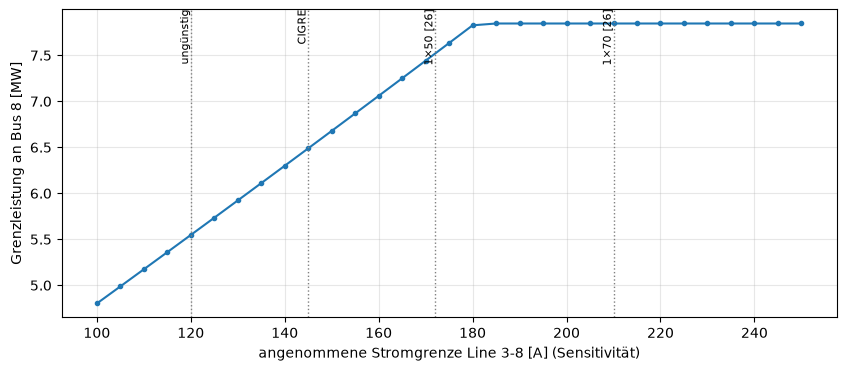

,Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
120,5.546775,Line 3-8,Line 2-3,59.395472
145,6.488459,Line 3-8,Line 2-3,75.733687
170,7.441835,Line 3-8,Line 2-3,93.786636
210,7.846177,Line 2-3,Line 1-2,100.685285
250,7.846177,Line 2-3,Line 1-2,100.685285


In [11]:
i_werte = np.arange(0.100, 0.2501, 0.005)
sens = {}
for i_max in i_werte:
    df = bus8[LF_HAUPT].copy()
    df[LEITUNG] = df[LEITUNG] * 0.145 / i_max                # gleicher Strom, andere Bezugsgröße
    sens[round(i_max * 1000)] = grenze(df)
sens = pd.DataFrame(sens).T
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sens.index, sens["Grenzleistung [MW]"].astype(float), "o-", ms=3)
for i, txt in ((120, "ungünstig"), (145, "CIGRE"), (172, "1×50 [26]"), (210, "1×70 [26]")):
    ax.axvline(i, color="gray", ls=":", lw=1)
    ax.text(i, ax.get_ylim()[1], txt, rotation=90, va="top", ha="right", fontsize=8)
ax.set_xlabel("angenommene Stromgrenze Line 3-8 [A] (Sensitivität)")
ax.set_ylabel("Grenzleistung an Bus 8 [MW]")
ax.grid(alpha=0.3)
plt.show()
plots.table(sens.loc[[120, 145, 170, 210, 250]], decimals=2)

**Ergebnis Sensitivität (nur Bewertung, nicht der Strom ändert sich):**

| angenommene Stromgrenze | Grenzleistung | erste Leitung |
|---|---|---|
| 120 A (ungünstige Verlegung) | 5,55 MW | Line 3-8 |
| **145 A (Referenznetz)** | **6,49 MW** | **Line 3-8** |
| 170 A (≈ 1×50 nach Datenblatt) | 7,44 MW | Line 3-8 |
| ab etwa 180 A (z. B. 210 A ≈ 1×70) | 7,85 MW | Line 2-3 |

- Die Grenzleistung steigt bis etwa 180 A linear mit der Stromgrenze, weil der Strom auf Line 3-8 nach der Umkehr fast linear mit der Einspeisung wächst.
- Ab etwa 180 A bestimmt nicht mehr Line 3-8 die Grenze, sondern Line 2-3. Eine höhere Stromgrenze bringt dann nichts mehr. Das zeigt schon vor jeder Maßnahme, wo der Engpass sich hin verlagern wird.
- Der Engpass auf Line 3-8 hängt also davon ab, mit welcher Belastbarkeit gerechnet wird. Mit den Datenblattwerten für 70 mm² unter Bezugsbedingungen wäre Line 3-8 kein Engpass. Deshalb wird im Weiteren bewusst der Wert des Referenznetzes verwendet.

## 6 Kapazitätserhöhung

### 6.1 Auswahl der Maßnahme

Zwei technische Maßnahmen werden verglichen:

- **Maßnahme A – Leitungsersatz:** Line 3-8 wird durch ein NA2XS2Y-Einleiterkabel 12/20 kV mit größerem Querschnitt ersetzt (pandapower-Standardtypen [25], Datenblattwerte [26]).
- **Maßnahme B – Parallelkabel:** Ein zweites Kabel `CABLE_CIGRE_MV` wird parallel verlegt (`parallel = 2`): doppelte Stromgrenze, halbe Impedanz.

Für jeden Querschnitt wird die Einspeisung an Bus 8 wieder linear erhöht (Hauptszenario). Gesucht ist der kleinste Querschnitt, ab dem nicht mehr Line 3-8 die Grenzleistung bestimmt; ein größerer Querschnitt bringt dann keinen Gewinn mehr, weil eine andere Leitung zuerst überlastet wird [19, S. 799 f.].

In [12]:
TYPEN = ["NA2XS2Y 1x70 RM/25 12/20 kV", "NA2XS2Y 1x95 RM/25 12/20 kV", "NA2XS2Y 1x120 RM/25 12/20 kV",
         "NA2XS2Y 1x150 RM/25 12/20 kV", "NA2XS2Y 1x185 RM/25 12/20 kV", "NA2XS2Y 1x240 RM/25 12/20 kV"]
idx38 = int(BASIS.line.index[BASIS.line["name"] == LEITUNG][0])

def ersatz(typ):
    return lambda n: pp.change_std_type(n, idx38, typ, element="line")

def parallel(n):
    n.line.at[idx38, "parallel"] = 2

varianten = {"vorher (CABLE_CIGRE_MV)": None, **{t.split(" RM")[0]: ersatz(t) for t in TYPEN}, "Parallelkabel (2 × CABLE_CIGRE_MV)": parallel}
st = pp.available_std_types(BASIS, "line")
auswahl = {}
for name, mod in varianten.items():
    n = netz(LF_HAUPT, leitung=mod)
    l = n.line.loc[idx38]
    auswahl[name] = {"R′ [Ω/km]": l.r_ohm_per_km, "X′ [Ω/km]": l.x_ohm_per_km, "C′ [nF/km]": l.c_nf_per_km,
                     "I_max [A]": l.max_i_ka * l.parallel * 1000,
                     "Z Line 3-8 [Ω]": abs(complex(l.r_ohm_per_km, l.x_ohm_per_km)) * l.length_km / l.parallel,
                     **grenze(sweep_einspeisung("Bus 8", leitung=mod))}
auswahl = pd.DataFrame(auswahl).T
plots.table(auswahl, decimals=3)

,R′ [Ω/km],X′ [Ω/km],C′ [nF/km],I_max [A],Z Line 3-8 [Ω],Grenzleistung [MW],erste Leitung,zweite Leitung,Auslastung zweite Leitung [%]
vorher (CABLE_CIGRE_MV),0.501000,0.716000,151.174900,145.000000,1.136037,6.488459,Line 3-8,Line 2-3,75.733687
NA2XS2Y 1x70,0.443000,0.132000,190.000000,220.000000,0.600922,7.858588,Line 2-3,Line 1-2,100.488212
NA2XS2Y 1x95,0.313000,0.132000,216.000000,252.000000,0.441604,7.843038,Line 2-3,Line 1-2,100.772864
NA2XS2Y 1x120,0.253000,0.119000,230.000000,283.000000,0.363466,7.836327,Line 2-3,Line 1-2,100.897316
NA2XS2Y 1x150,0.206000,0.116000,250.000000,319.000000,0.307339,7.831230,Line 2-3,Line 1-2,100.992575
NA2XS2Y 1x185,0.161000,0.117000,273.000000,362.000000,0.258729,7.826391,Line 2-3,Line 1-2,101.083448
NA2XS2Y 1x240,0.122000,0.112000,304.000000,421.000000,0.215298,7.822822,Line 2-3,Line 1-2,101.151997
Parallelkabel (2 × CABLE_CIGRE_MV),0.501000,0.716000,151.174900,290.000000,0.568019,7.831909,Line 2-3,Line 1-2,100.973347


In [13]:
MASSNAHME_A = next(name for name in auswahl.index[1:-1] if auswahl.loc[name, "erste Leitung"] != LEITUNG)
MASSNAHMEN = {"vorher": None, f"A: {MASSNAHME_A}": varianten[MASSNAHME_A], "B: Parallelkabel": parallel}
print("Maßnahme A (kleinster Querschnitt, ab dem Line 3-8 nicht mehr begrenzt):", MASSNAHME_A)

Maßnahme A (kleinster Querschnitt, ab dem Line 3-8 nicht mehr begrenzt): NA2XS2Y 1x70


**Auswahl der Maßnahme:**

- Schon das kleinste untersuchte Kabel, **NA2XS2Y 1×70 12/20 kV** (220 A [25]; nach Datenblatt in Erde 210 A [26]), hebt den Engpass auf Line 3-8 auf. Die Grenzleistung steigt von 6,49 auf 7,86 MW, danach ist Line 2-3 zuerst überlastet.
- Größere Querschnitte bringen **keinen** weiteren Gewinn (7,82 bis 7,86 MW), weil Line 2-3 die Grenze bestimmt. Nach dem Grundsatz, den kleinsten ausreichenden genormten Querschnitt zu wählen [19, S. 799 f.], ist das 1×70-Kabel die Maßnahme A.
- **Parallelkabel (Maßnahme B):** doppelte Stromgrenze (290 A) und halbe Impedanz. Es erreicht dieselbe Grenzleistung (7,83 MW).
- Beide Maßnahmen halbieren die Impedanz von Line 3-8 etwa (1,14 → 0,60 bzw. 0,57 Ω). Beim 1×70-Kabel liegt das nicht am Widerstand (R′ fast gleich), sondern an der viel kleineren Reaktanz (X′ 0,132 statt 0,716 Ω/km).

### 6.2 Vorher und Nachher unter identischen Randbedingungen

Gleiche Einspeisung (Grenzleistung aus 3.3) an Bus 8, gleiche Last (60 %), für alle acht Schaltzustände. Alle Werte als Differenz **nachher − vorher**.

In [14]:
def zustand(mod, key):
    n = grenzbetrieb("Bus 8", P_GRENZ, key=key, leitung=mod)
    return {"I": pd.Series(n.res_line.i_ka.to_numpy() * 1000, index=n.line["name"]),
            "A": pd.Series(n.res_line.loading_percent.to_numpy(), index=n.line["name"]),
            "P": pd.Series(n.res_line.p_from_mw.to_numpy(), index=n.line["name"]),
            "U": pd.Series(n.res_bus.vm_pu.to_numpy(), index=n.bus["name"]),
            "T": pd.Series(n.res_trafo.loading_percent.to_numpy(), index=n.trafo["name"]),
            "V": float(n.res_line.pl_mw.sum() + n.res_trafo.pl_mw.sum()),
            "Ptr": pd.Series(n.res_trafo.p_hv_mw.to_numpy(), index=n.trafo["name"])}

vergleich = {m: {k: zustand(mod, k) for k in KEYS} for m, mod in MASSNAHMEN.items()}
NACH = [m for m in MASSNAHMEN if m != "vorher"]

def diff(groesse, m, faktor=1.0):
    return pd.DataFrame({LABEL[k]: (vergleich[m][k][groesse] - vergleich["vorher"][k][groesse]) * faktor for k in KEYS})

for m in NACH:
    print(f"{m}: Änderung der Auslastung aller Leitungen [Prozentpunkte]")
    display(plots.table(diff("A", m), decimals=1, cmap="RdBu_r", vmin=-40, vmax=40))

A: NA2XS2Y 1x70: Änderung der Auslastung aller Leitungen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.2,-0.2,-0.2,-0.1,2.5,1.3,1.5,1.0
Line 2-3,-0.2,-0.2,-0.2,-0.2,2.5,1.3,1.5,1.0
Line 3-4,-0.0,-9.9,-4.4,-12.9,-0.0,6.0,4.3,-1.9
Line 4-5,-0.0,-0.0,-7.6,-3.1,-0.0,0.0,0.6,2.2
Line 5-6,-0.0,-0.0,-8.0,-3.9,-0.0,0.0,-4.0,-2.0
Line 7-8,-0.0,-0.0,-8.0,-3.8,0.0,0.0,-4.3,-2.2
Line 8-9,-0.0,-11.0,-0.0,-7.5,0.0,-6.3,0.0,-4.2
Line 9-10,-0.0,-11.9,-0.0,-8.3,0.0,-6.8,0.0,-4.6
Line 10-11,-0.0,-12.1,-0.0,-8.6,0.0,-6.9,0.0,-4.7


B: Parallelkabel: Änderung der Auslastung aller Leitungen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,0.1,0.0,0.0,-0.0,2.0,1.1,1.2,0.8
Line 2-3,0.1,-0.0,0.0,-0.0,1.9,1.0,1.2,0.8
Line 3-4,-0.0,-9.4,-4.2,-13.9,-0.0,5.6,4.1,-2.8
Line 4-5,-0.0,-0.0,-8.4,-2.8,-0.0,-0.0,-0.2,2.2
Line 5-6,-0.0,-0.0,-9.0,-4.7,-0.0,-0.0,-4.7,-2.5
Line 7-8,0.0,0.0,-9.0,-4.6,0.0,0.0,-4.7,-2.5
Line 8-9,0.0,-13.5,0.0,-9.7,0.0,-7.6,0.0,-5.3
Line 9-10,0.0,-13.6,0.0,-9.8,0.0,-7.6,0.0,-5.3
Line 10-11,0.0,-13.6,0.0,-9.9,0.0,-7.6,0.0,-5.3


In [15]:
print("Auslastung aller Leitungen vorher und nachher [%]")
absolut = pd.concat({m: pd.DataFrame({LABEL[k]: vergleich[m][k]["A"] for k in KEYS}) for m in MASSNAHMEN}, axis=1)
plots.table(absolut, decimals=1, cmap="YlOrRd", vmin=0, vmax=110)

Auslastung aller Leitungen vorher und nachher [%]


In [16]:
for m in NACH:
    print(f"{m}: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)")
    display(plots.table(diff("P", m), decimals=3, cmap="RdBu_r", vmin=-2, vmax=2))

A: NA2XS2Y 1x70: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.005,0.000,-0.001,0.001,-0.120,-0.061,-0.071,-0.046
Line 2-3,-0.005,0.001,-0.001,0.001,-0.121,-0.062,-0.072,-0.047
Line 3-4,-0.000,0.736,0.497,0.753,-0.000,0.442,0.277,0.443
Line 4-5,-0.000,-0.000,0.497,0.243,-0.000,0.000,0.277,0.143
Line 5-6,-0.000,-0.000,0.498,0.243,-0.000,0.000,0.277,0.143
Line 7-8,0.000,0.000,0.499,0.244,0.000,-0.000,0.278,0.143
Line 8-9,-0.000,-0.742,-0.000,-0.514,0.000,-0.444,0.000,-0.301
Line 9-10,-0.000,-0.741,-0.000,-0.513,0.000,-0.444,0.000,-0.301
Line 10-11,-0.000,-0.738,-0.000,-0.512,0.000,-0.443,0.000,-0.300


B: Parallelkabel: Änderung des Wirkleistungsflusses p_from_mw [MW] (Lastflussverteilung)


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Line 1-2,-0.020,-0.011,-0.012,-0.008,-0.103,-0.056,-0.063,-0.043
Line 2-3,-0.020,-0.011,-0.012,-0.008,-0.104,-0.056,-0.064,-0.044
Line 3-4,-0.000,0.707,0.468,0.753,-0.000,0.394,0.244,0.407
Line 4-5,-0.000,-0.000,0.468,0.243,-0.000,-0.000,0.244,0.131
Line 5-6,-0.000,-0.000,0.468,0.243,-0.000,-0.000,0.244,0.131
Line 7-8,-0.000,-0.000,0.470,0.244,-0.000,-0.000,0.245,0.132
Line 8-9,0.000,-0.713,0.000,-0.514,0.000,-0.396,0.000,-0.277
Line 9-10,0.000,-0.712,0.000,-0.513,0.000,-0.395,0.000,-0.277
Line 10-11,0.000,-0.710,0.000,-0.512,0.000,-0.394,0.000,-0.276


In [17]:
for m in NACH:
    print(f"{m}: Änderung der Spannung an allen Bussen [Prozentpunkte]")
    display(plots.table(diff("U", m, 100), decimals=2, cmap="RdBu", vmin=-1.5, vmax=1.5))

A: NA2XS2Y 1x70: Änderung der Spannung an allen Bussen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,0.03,0.02,0.02,0.01,-0.02,-0.02,-0.02,-0.01
Bus 2,0.06,0.03,0.04,0.03,-0.01,-0.01,-0.01,-0.01
Bus 3,0.10,0.06,0.07,0.05,0.01,-0.01,-0.01,-0.01
Bus 4,0.10,0.07,0.07,0.07,0.01,-0.01,-0.01,-0.01
Bus 5,0.10,0.07,0.08,0.08,0.01,-0.01,-0.01,-0.01
Bus 6,0.10,0.07,0.10,0.09,0.01,-0.01,-0.01,-0.00
Bus 7,0.08,0.12,0.10,0.10,-0.04,-0.01,-0.01,-0.00
Bus 8,0.08,0.12,0.12,0.11,-0.04,-0.01,-0.01,0.00


B: Parallelkabel: Änderung der Spannung an allen Bussen [Prozentpunkte]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
name,,,,,,,,
Bus 0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Bus 1,0.03,0.02,0.02,0.02,0.01,0.01,0.01,0.01
Bus 2,0.06,0.05,0.05,0.04,0.06,0.04,0.04,0.03
Bus 3,0.11,0.08,0.09,0.07,0.13,0.08,0.09,0.07
Bus 4,0.11,0.04,0.06,0.03,0.13,0.05,0.07,0.04
Bus 5,0.11,0.04,0.03,0.01,0.13,0.05,0.05,0.03
Bus 6,0.11,0.04,-0.04,-0.03,0.13,0.05,0.00,0.00
Bus 7,-0.24,-0.11,-0.05,-0.03,-0.10,-0.05,-0.00,-0.00
Bus 8,-0.24,-0.11,-0.14,-0.08,-0.10,-0.05,-0.05,-0.03


In [18]:
zeilen = {}
for m in MASSNAHMEN:
    for k in KEYS:
        v = vergleich[m][k]
        zeilen[(m, LABEL[k])] = {"Verluste [kW]": v["V"] * 1000, "Line 3-8 [%]": v["A"][LEITUNG],
                                 "höchstbelastete Leitung": v["A"].idxmax(), "Auslastung [%]": v["A"].max(),
                                 "U max MS [pu]": v["U"][MS_BUSSE].max(), "U min MS [pu]": v["U"][MS_BUSSE].min(),
                                 "Trafo 0-1 [%]": v["T"]["Trafo 0-1"], "Trafo 0-12 [%]": v["T"]["Trafo 0-12"]}
uebersicht = pd.DataFrame(zeilen).T
display(plots.table(uebersicht, decimals=3))
verl = pd.DataFrame({m: [vergleich[m][k]["V"] * 1000 - vergleich["vorher"][k]["V"] * 1000 for k in KEYS] for m in NACH},
                    index=[LABEL[k] for k in KEYS])
print("Änderung der Verluste [kW]")
verl.round(1).T

Änderung der Verluste [kW]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
A: NA2XS2Y 1x70,-5.4,0.4,-1.1,0.9,-3.8,-1.1,-1.7,-0.7
B: Parallelkabel,-20.1,-11.0,-12.3,-8.5,-8.0,-4.6,-4.7,-3.4


**Vorher und Nachher bei gleicher Einspeisung (6,49 MW, 60 % Last):**

- **Line 3-8:** Im Normalzustand sinkt die Auslastung von 100 % auf 66 % (A) bzw. 50 % (B). In den anderen Zuständen sinkt sie ebenfalls (um 4 bis 50 Prozentpunkte).
- **Lastflussverteilung im Normalzustand:** Sie bleibt unverändert. Im Strahlennetz bestimmen Einspeisung und Lasten die Flüsse, die Impedanz einer Leitung ändert nur deren Strom-Bezugsgröße und Verluste.
- **Lastflussverteilung in vermaschten Zuständen:** Die Maßnahme verschiebt Leistung, weil Line 3-8 jetzt eine niedrigere Impedanz hat und mehr Leistung an sich zieht [19, S. 437 f.].
  - **S2 und S3:** Die Leitungen der Maschen werden um 4 bis 14 Prozentpunkte entlastet.
  - **S1:** Mehr Einspeisung fließt über Line 3-8 nach Abgang 1 statt über die Kupplung nach Abgang 2. Line 1-2 und 2-3 steigen um 1 bis 2,5 Prozentpunkte, Abgang 2 sinkt um 1 bis 2 Prozentpunkte.
- **Spannungen:** Sie ändern sich an allen Bussen um höchstens 0,25 Prozentpunkte. Mit dem Parallelkabel sinkt die Spannung an Bus 7 bis 11 leicht (bis −0,24 Prozentpunkte), weil der Spannungsanstieg über Line 3-8 kleiner wird.
- **Verluste:** Im Normalzustand sinken sie um 5 kW (A, −3 %) bzw. 20 kW (B, −11 %). In den anderen Zuständen ist die Änderung kleiner; mit A steigen sie bei geschlossenem S3 sogar minimal.
- **Neue Engpässe:** Bei dieser Einspeisung gibt es keine. Line 2-3 und 1-2 bleiben bei 75 %.

## 7 Entschärft oder verlagert?

Mit Maßnahme wird die Einspeisung an Bus 8 erneut linear erhöht, bis die nächste Leitung 100 % erreicht, in allen Schaltzuständen. So zeigt sich, wie viel zusätzliche Leistung die Maßnahme ermöglicht und welche Leitung danach den Engpass bildet.

In [19]:
nachher = {m: {k: sweep_einspeisung("Bus 8", key=k, leitung=mod) for k in KEYS} for m, mod in MASSNAHMEN.items()}
zeilen = {}
for k in KEYS:
    for m in MASSNAHMEN:
        g = grenze(nachher[m][k])
        zeilen[(LABEL[k], m)] = {**g}
    zeilen[(LABEL[k], "vorher")]["Gewinn [MW]"] = 0.0
    for m in NACH:
        zeilen[(LABEL[k], m)]["Gewinn [MW]"] = zeilen[(LABEL[k], m)]["Grenzleistung [MW]"] - zeilen[(LABEL[k], "vorher")]["Grenzleistung [MW]"]
verlagerung = pd.DataFrame(zeilen).T
plots.table(verlagerung, decimals=2)

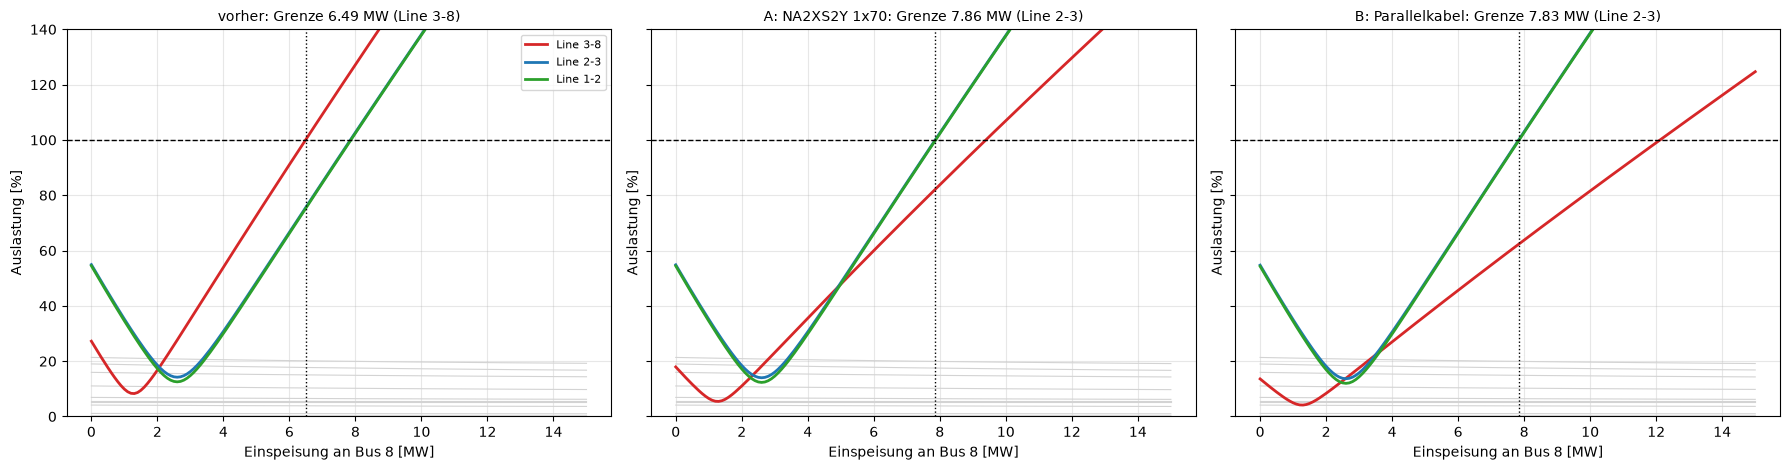

In [20]:
fig, axes = plt.subplots(1, len(MASSNAHMEN), figsize=(18, 4.8), sharey=True)
for ax, m in zip(axes, MASSNAHMEN):
    lastfluss_plot(ax, nachher[m]["000"], linear=False)
    g = grenze(nachher[m]["000"])
    ax.axvline(g["Grenzleistung [MW]"], color="black", ls=":", lw=1)
    ax.set_title(f"{m}: Grenze {g['Grenzleistung [MW]']:.2f} MW ({g['erste Leitung']})", fontsize=10)
    ax.set_ylim(0, 140)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Neuer Grenzbetriebspunkt mit A: NA2XS2Y 1x70: 7.86 MW, erste Leitung Line 2-3


,Typ,Länge [km],parallel,I [A],I_max [A],Auslastung [%],P von from_bus [MW]
name,,,,,,,
Line 2-3,CABLE_CIGRE_MV,4.4,1.0,145.0,145.0,100.0,-5.1
Line 1-2,CABLE_CIGRE_MV,2.8,1.0,144.7,145.0,99.8,-5.0
Line 3-8,NA2XS2Y 1x70 RM/25 12/20 kV,1.3,1.0,180.7,220.0,82.1,-6.5
Line 3-4,CABLE_CIGRE_MV,0.6,1.0,28.9,145.0,19.9,1.0
Line 8-9,CABLE_CIGRE_MV,0.3,1.0,25.4,145.0,17.5,0.9
Line 4-5,CABLE_CIGRE_MV,0.6,1.0,21.6,145.0,14.9,0.8
Line 9-10,CABLE_CIGRE_MV,0.8,1.0,14.8,145.0,10.2,0.5
Line 5-6,CABLE_CIGRE_MV,1.5,1.0,9.3,145.0,6.4,0.3
Line 12-13,OHL_CIGRE_MV,4.9,1.0,10.9,195.0,5.6,0.3


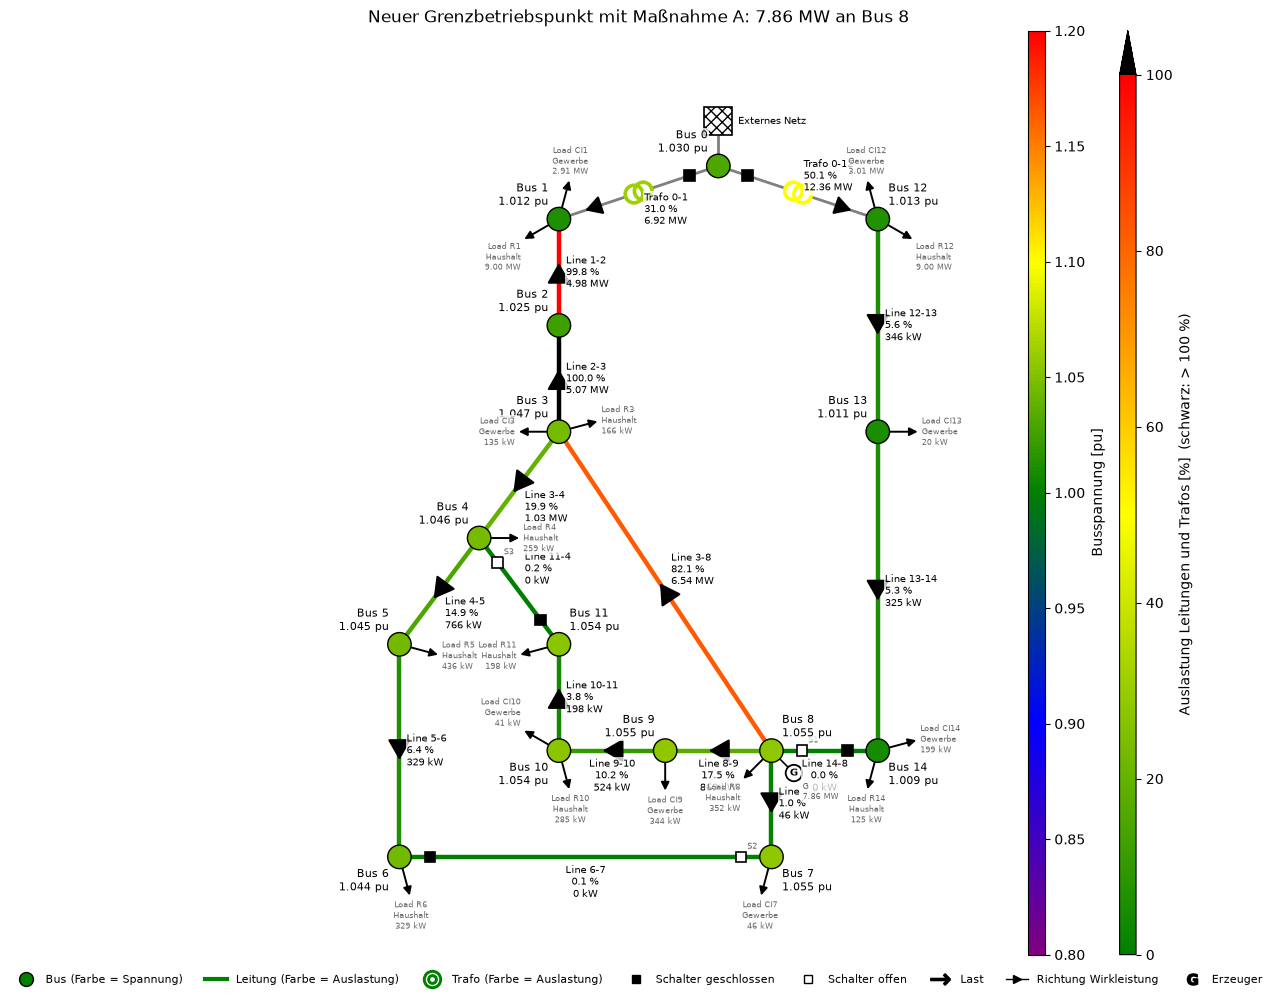

In [21]:
m_a = f"A: {MASSNAHME_A}"
g = grenze(nachher[m_a]["000"])
n_neu = grenzbetrieb("Bus 8", round(g["Grenzleistung [MW]"], 2), leitung=MASSNAHMEN[m_a])
print(f"Neuer Grenzbetriebspunkt mit {m_a}: {g['Grenzleistung [MW]']:.2f} MW, erste Leitung {g['erste Leitung']}")
display(plots.table(leitungstabelle(n_neu), decimals=1))
_ = netplan.plot_static(n_neu, title=f"Neuer Grenzbetriebspunkt mit Maßnahme A: {g['Grenzleistung [MW]']:.2f} MW an Bus 8")

**Entschärft oder verlagert?**

| Zustand | vorher | A: NA2XS2Y 1×70 | B: Parallelkabel | Engpass danach |
|---|---|---|---|---|
| alle offen | 6,49 MW (Line 3-8) | 7,86 MW (+1,37) | 7,83 MW (+1,34) | Line 2-3 |
| S1 zu | 11,85 MW (Line 3-8) | 14,36 MW (+2,51) | 14,43 MW (+2,59) | Line 1-2 |
| S2 und/oder S3 zu | 7,83 MW (Line 2-3) | ±0,01 MW | ±0,01 MW | Line 2-3 |
| S1 mit S2/S3 zu | 14,5–14,7 MW (Line 1-2) | −0,25 bis −0,40 MW | −0,24 bis −0,37 MW | Line 1-2 |

- **Der Engpass wird verlagert, nicht beseitigt.** Im Normalzustand steigt die aufnehmbare Leistung um rund 1,4 MW (+21 %). Danach erreicht Line 2-3 die Grenze, Line 1-2 liegt mit 99,8 % gleichauf. Line 3-8 ist im neuen Grenzpunkt nur noch zu 82 % ausgelastet.
- **In den Maschenzuständen** bringt die Maßnahme nichts, weil Line 3-8 dort ohnehin nicht der Engpass war.
- **Mit S1 und einer Masche** sinkt die Grenzleistung sogar leicht. Die niedrigere Impedanz von Line 3-8 zieht mehr Einspeisung in Richtung Abgang 1 und damit auf Line 1-2, statt sie über die Kupplung nach Abgang 2 zu leiten. Das ist der in [19, S. 437 f.] beschriebene Effekt, dass Leitungen niedriger Impedanz in Maschen zusätzlich belastet werden.
- **Konsequenz:** Für mehr Einspeisung an Bus 8 müssten auch Line 2-3 und 1-2 verstärkt werden, zusammen 7,2 km Kabel statt 1,3 km. Alternativ lässt sich die Grenze ohne Leitungsbau verschieben: durch Spitzenkappung (Abregelung von höchstens 3 % der Jahresenergie, EnWG § 11 Abs. 2 [39]) oder durch einen Anschluss großer Anlagen direkt an der Umspannwerks-Sammelschiene, wie in Teil 4.

## 8 Fazit

- **Laständerung allein** kann Line 3-8 nicht zuerst überlasten: Die vorgelagerten Kabel Line 2-3 und 1-2 tragen die Summe aller Lasten dahinter und erreichen ihre Grenze immer zuerst.
- **Einspeisung am Ende von Line 3-8 (Bus 8)** macht die Leitung zum Engpass, weil die Einspeisung zuerst über Line 3-8 zurückfließt. Grenzbetriebspunkt bei 60 % Last und alle Schalter offen: **6,49 MW**. Line 3-8 führt dann 145 A von 145 A, Line 2-3 und 1-2 rund 110 A (76 %), alle anderen Leitungen höchstens 20 %.
- **Schalterstellungen:** Mit S1 bleibt Line 3-8 der Engpass, aber erst bei 11,85 MW. Mit S2 oder S3 liegt Line 3-8 in einer Masche und kann nie zuerst überlastet werden.
- **Stromgrenze:** 145 A sind für ein Al-Kabel mit 50 bis 70 mm² vorsichtig angesetzt (Datenblatt in Erde 172 bis 210 A). Mit mehr als etwa 180 A wäre Line 3-8 kein Engpass mehr.
- **Kapazitätserhöhung:** Ein NA2XS2Y 1×70 oder ein Parallelkabel hebt den Engpass auf Line 3-8 auf und erhöht die aufnehmbare Leistung um etwa 1,4 MW (+21 %). Größere Querschnitte bringen nichts mehr. Spannungen ändern sich kaum, die Verluste sinken leicht.
- **Bewertung:** Der Engpass wird auf Line 2-3 und 1-2 **verlagert**. In vermaschten Zuständen zieht die stärkere Leitung zusätzlich Leistung an und kann die Grenze sogar leicht senken. Eine echte Entlastung bräuchte die Verstärkung des ganzen Wegs bis Bus 1 oder Maßnahmen ohne Leitungsbau (Blindleistung, Spitzenkappung), die in Teil 9 aufgegriffen werden.

### Quellen

Nummern wie im zentralen Quellenverzeichnis (`Task4-Datengrundlage.ipynb`, Abschnitt 3).

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0.

[25] pandapower, „Standard Type Libraries“ und `create_cigre_network_mv`, Dokumentation, Version 3.x. Online: https://pandapower.readthedocs.io

[26] Zuhmann, „Mittelspannungskabel NA2XS2Y nach VDE 0276-620“, Datenblatt (Ausgabe 13.07.2016). Online: https://www.zuhmann.info/media/daten/019.pdf

[27] DIN VDE 0276-620 (VDE 0276-620), „Starkstromkabel – Energieverteilungskabel mit extrudierter Isolierung für Nennspannungen von 3,6/6 (7,2) kV bis einschließlich 20,8/36 (42) kV“, Berlin: VDE Verlag.

[28] DIN VDE 0276-1000 (VDE 0276-1000), „Starkstromkabel – Strombelastbarkeit, Allgemeines, Umrechnungsfaktoren“, Berlin: VDE Verlag.

[39] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 11 Abs. 2 (Spitzenkappung). Online: https://www.gesetze-im-internet.de/enwg_2005/__11.html
